# QPDK hyperbolic lattice chip: a {7,3} flake of 42 CPW edge resonators (Quantcore PDK rebuild)

**What the chip is.** gdsfactory **quantum-rf-pdk** (QPDK) `qpdk/samples/hyperbolic_lattice_chip.py`, which places
`hyperbolic_lattice` from `qpdk/cells/hyperbolic.py` on a chip edge; the tiling maths is `qpdk/hyperbolic.py`.
<https://github.com/gdsfactory/quantum-rf-pdk>, **MIT licence** (gdsfactory 2024; read from a local clone, never
executed). Spec: `docs/designs/qpdk/hyperbolic_lattice_chip.md`. The layout follows the edge-resonator scheme of
A. J. Kollár, M. Fitzpatrick and A. A. Houck, *Hyperbolic lattices in circuit quantum electrodynamics*, Nature
**571**, 45–50 (2019): identical CPW resonators sit on the edges of a {p, q} tiling of the Poincaré disk and meet at
capacitive couplers on its vertices, so photons hop on the line graph of the tiling. Here {p, q} = {7, 3} with one
shell: the central heptagon and the seven heptagons around it, mapped onto a disk of 6000 µm radius. Every edge is one
resonator of exactly 7500 µm (pin rim to pin rim), every vertex a three-pin capacitive disk coupler; free boundary
pins get a 400 µm shorted stub, two of them (QPDK's `probe_pins = (11, 0)`) are fed out to launchers. No qubits.

This notebook **rebuilds** the chip on the Quantcore PDK (not a replica); we distribute the rebuild under GPL-3.0.
The tiling is computed in the notebook from standard hyperbolic geometry (no QPDK code is used).

| topic | QPDK source | this rebuild (Quantcore PDK) |
|---|---|---|
| die | the lattice's bounding box + a 500 µm `edge_margin`, QPDK `chip_edge` | **14 × 14 mm**: the 6000 µm disk the tiling is mapped onto, centred, plus the two launchers on the pad rule; Quantcore die frame, device ID "QPDK-HYP" |
| tiling | {7,3}, one shell, unit disk × 6000 µm, a vertex on +x | the same, computed here (vertex numbering as QPDK's, so free pins 0 and 11 are the same pins) |
| couplers | `hyperbolic_vertex_coupler`: 40 µm disk, three pie-slice pins, 4 µm radial gaps, 6 µm ground ring, 20 µm leads, pins along the geodesic tangents | the library's `HyperbolicVertexCoupler` (a re-drawing of the same cell) with the same parameters |
| resonators | `hyperbolic_edge_resonator`: 7500 µm rim to rim, legs 60 µm apart (bend r 30 µm), 25 µm margin inside the region of the two vertices and the two face centroids | the same length, region and margin; the meander is a serpentine computed here and drawn with `d.route(..., nodes=..., meander=7460)` (legs at least 62 µm apart) |
| stubs, probes | 400 µm shorted stubs; probe feeds 1000 µm along the pin, then onto the nearest axis into a QPDK `launcher` | the same stubs; probe lines to `BondPad` launchers 100 µm (`frame.pad_edge`) from the die edge, so the lines are longer |
| substrate | Al on Si (εr 11.45) | sapphire 650 µm, εr 10.25 (frequencies are not the QPDK ones) |
| junctions | none | none |
| cheese | none | the **PDK band** (chip `cheese: "auto"`, at least 4 µm clear of 3/0) |

**Simplified:** the probe lines end on `BondPad` launchers at the pad rule, so they are longer than QPDK's feeds: F1
runs straight west (its pin already points along −x), F2 keeps QPDK's corner 1000 µm along its pin and runs east from
there. QPDK clips the outer
apex of a boundary edge's region at the bisector with the next boundary edge; on this flake no apex reaches it, so the
rebuild leaves that step out (the DRC checks the result).

**How this notebook goes.** First the lattice geometry (the tiling, its pins and its regions), then the **Design**:
the chip one segment at a time, each segment its own cell with a picture of the chip so far (the die, the two
launchers, the 35 vertex couplers, the 42 edge resonators, the 19 boundary stubs, the two probe lines, and then the
whole chip). Then the same steps as the Flow strip of the Quantcore KLayout plugin: **Check** (DRC, netlist) → **LOM**
(simulation and plots) → **Simulate** (export to HFSS, the component simulation, the eigenmode simulation, the
full-wave run) → **Results** (plots, the values, FEM against the LOM, a feedback step and the iteration to a target)
→ **Fab**.

**Nothing here solves on its own.** The switches (the code cell after Setup) are off (`RUN_FEM = False`): FEM results
are loaded when a solve has been kept, otherwise each FEM cell says what would appear.

## Setup

The imports, the output folders and the switches. `_qpdk` holds the QPDK cell defaults shared by the QPDK notebooks
(the launcher, the CPW bend radius). `FULL_FAB = False` skips the fab-only corner rounding in Fab 1 (`qcc mask` writes
the full file). The segment pictures go to `build/snapshots/hyperbolic_lattice_chip/` (not kept in the repo), the final
snapshots next to the notebook.

`LIVE`: with KLayout open (the default) every change below is pushed to the KLayout window as you run it; with
`QCC_LIVE=0` the notebook builds headless and only writes files. `_common` holds the helpers the design notebooks share
(tables, snapshots, the PDK placement, the FEM and feedback steps).

**The switches** (next cell): `RUN_FEM` solves the FEM jobs in AEDT 2024 R1 or newer, one after the other (a new
non-graphical AEDT unless `AEDT_MODE` says otherwise; an AEDT you have open is never touched); `RESOLVE` solves again
even when kept results match; `FEM_FAST` exports with the library's fast test settings (minutes, values not
converged); `MAX_ITER` caps the feedback iterations towards the target.

In [2]:
%config InlineBackend.figure_formats = ["png"]
import cmath, math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
sys.path.insert(0, str(ROOT / "examples" / "designs" / "qpdk"))
from _common import *                            # tables, snapshots, PDK and FEM step helpers
import _qpdk as QP                               # QPDK cell defaults (launcher, CPW bend radius)
from quantcore_circuits.designer import Designer
import numpy as np
LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
FULL_FAB = False                                 # True: also round the corners in the fab export
OUT = Path("examples/designs/qpdk")              # design JSON + final snapshots
STEPS = Path("build/snapshots/hyperbolic_lattice_chip")   # step-by-step snapshots (build/ is not kept in the repo)
W = H = 14000.0                                  # the die (µm): the 6000 µm disk plus the launchers
C0 = complex(W / 2, H / 2)                       # centre of the Poincaré disk on the chip

In [3]:
RUN_FEM = False        # True (or a set such as {"q3d_cmatrix"}): solve the FEM jobs in AEDT 2024 R1+, one at a time
RESOLVE = False        # True (or a set of analyses): solve again even when kept results match
FEM_FAST = True        # True: the library's fast test settings (minutes, not converged); False: the settings as written
AEDT_MODE = "batch"    # "batch" (no window) | "gui" (a new AEDT window, left open) | "attach" (the AEDT you have open)
MAX_ITER = 3           # feedback iterations towards the target (Results 5)

## The Quantcore PDK this chip uses

Every rule below comes from the PDK object (`get_pdk()`), not from this notebook: the stack feeds the LOM estimates and
the FEM exports, the frame and pad rule shape the die, and the cheese, 3/0 keep-out and corner-rounding rules apply
when the mask is written.

In [4]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | 5 µm squares, 20 µm gaps, ≥ 4 µm from the 3/0 keep-outs: a band of 3 rows around them, or the whole die (`cheese: "chip"`); an original design's own rule or holes where it has them (chip param `cheese`: auto / pdk / chip / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

**Junctions:** none on this chip (resonators and capacitive couplers only), so the PDK junction rule is not used.

## The lattice: the {7,3} tiling in the Poincaré disk

The geometry every segment below uses, computed here; nothing is placed yet. In the Poincaré disk (curvature −1) a
regular p-gon whose corners meet q at a time has circumradius R with cosh R = cot(π/p) cot(π/q); its corners sit at
Euclidean radius r₀ = tanh(R/2) (0.3007 for {7,3}). Geodesics are circle arcs that meet the unit circle at right angles
(or diameters), and the reflection across a geodesic is the inversion in its circle. The shell is the central heptagon
reflected across each of its seven edges (standard hyperbolic geometry, e.g. A. F. Beardon, *The Geometry of
Discrete Groups*, ch. 7; the resonator scheme is that of Kollár et al. 2019). The disk model is conformal, so the three geodesics at a vertex leave it exactly 120° apart: a three-pin coupler
with pins 120° apart fits every vertex, its pins along the geodesic tangents.

Vertices are numbered as QPDK numbers them: the central heptagon first (a vertex on +x, counter-clockwise), then each
outer heptagon in turn, each vertex where it is first reached. Pin 0 of a vertex carries its lowest-numbered edge,
and the free pins are listed in vertex order, so QPDK's `probe_pins = (11, 0)` are the same two pins here. On the chip
the unit disk is 6000 µm and the edges are drawn as straight chords; the pins keep the geodesic directions.

In [5]:
P_, Q_, R_DISK = 7, 3, 6000.0                   # {p, q} = {7, 3}, one shell; the unit disk is 6000 µm on the chip


def central_radius(p, q):
    # Poincaré radius of the central p-gon's corners: tanh(R/2), cosh R = cot(π/p) cot(π/q)
    return math.tanh(math.acosh(1 / (math.tan(math.pi / p) * math.tan(math.pi / q))) / 2)


def geodesic(a, b):
    # centre and radius of the circle through a and b orthogonal to the unit circle; None for a diameter
    c = 1 / a.conjugate()                       # a's inverse point lies on the same circle
    m = np.array([[2 * (b - a).real, 2 * (b - a).imag], [2 * (c - a).real, 2 * (c - a).imag]])
    if abs(np.linalg.det(m)) < 1e-12:
        return None
    rhs = np.array([abs(b) ** 2 - abs(a) ** 2, abs(c) ** 2 - abs(a) ** 2])
    x, y = np.linalg.solve(m, rhs)
    return complex(x, y), abs(a - complex(x, y))


def reflect(z, a, b):
    # z reflected across the geodesic through a and b: inversion in its circle (a mirror for a diameter)
    g = geodesic(a, b)
    if g is None:
        u = (b - a) / abs(b - a)
        return a + u * u * (z - a).conjugate()
    c, rho = g
    return c + rho * rho / (z - c).conjugate()


def tangent(a, b):
    # unit vector along which the geodesic from a to b leaves a
    g = geodesic(a, b)
    if g is None:
        return (b - a) / abs(b - a)
    t = 1j * (a - g[0])
    t /= abs(t)
    return t if (t.conjugate() * (b - a)).real > 0 else -t


r0 = central_radius(P_, Q_)
central = [r0 * cmath.exp(2j * math.pi * k / P_) for k in range(P_)]
verts, _seen = [], {}


def vid(z):                                     # vertex index, numbered in the order first reached
    key = (round(z.real, 9), round(z.imag, 9))
    if key not in _seen:
        _seen[key] = len(verts)
        verts.append(z)
    return _seen[key]


faces = [[vid(z) for z in central]]
for k in range(P_):                             # shell 1: the central heptagon reflected across each edge
    a, b = central[k], central[(k + 1) % P_]
    faces.append([vid(z) for z in [reflect(z, a, b) for z in central][::-1]])   # reversed: counter-clockwise again
edges = list(dict.fromkeys((min(i, j), max(i, j)) for f in faces for i, j in zip(f, f[1:] + f[:1])))
at_vertex = {v: [e for e, ij in enumerate(edges) if v in ij] for v in range(len(verts))}

pins = []                                       # per vertex: (direction of pin 0 in degrees, edge on pin k or -1)
for v in range(len(verts)):
    angles = [math.degrees(cmath.phase(tangent(verts[v], verts[sum(edges[e]) - v]))) for e in at_vertex[v]]
    rot, wiring = angles[0], [-1] * Q_
    for e, ang in zip(at_vertex[v], angles):
        k = round(((ang - rot) % 360) / (360 / Q_)) % Q_
        assert wiring[k] == -1, f"two edges on pin {k} of vertex {v}"
        wiring[k] = e
    pins.append((rot, wiring))
free = [(v, k) for v, (_, w) in enumerate(pins) for k in range(Q_) if w[k] == -1]

cent = [complex(round((C0 + R_DISK * z).real, 3), round((C0 + R_DISK * z).imag, 3)) for z in verts]   # on the chip


def unit(deg):
    return cmath.exp(1j * math.radians(deg))


def pin_dir(v, k):                              # pin k of vertex v: its outward direction on the chip
    return unit(pins[v][0] + 360 * k / Q_)


def xy(z):
    return (round(z.real, 3), round(z.imag, 3))


deg = [len(at_vertex[v]) for v in range(len(verts))]
off120 = max(abs(((pins[v][0] + 120 * k - math.degrees(cmath.phase(tangent(verts[v], verts[sum(edges[e]) - v]))))
                  + 180) % 360 - 180) for v in range(len(verts)) for k, e in enumerate(pins[v][1]) if e >= 0)
chords = sorted({round(abs(cent[j] - cent[i]), 1) for i, j in edges})
print(f"r0 = {r0:.4f}; V = {len(verts)}, E = {len(edges)}, F = {len(faces)}, V - E + F = {len(verts) - len(edges) + len(faces)}")
print(f"degree 3: {deg.count(3)} vertices, degree 2 (boundary): {deg.count(2)}; free pins {len(free)}; "
      f"largest pin-to-geodesic misfit {off120:.1e}°")
print(f"chord lengths on the chip (µm): {chords}; outermost vertex {max(abs(c - C0) for c in cent):.0f} µm from the centre")
print(f"probe pins: free pin 11 = vertex {free[11][0]} pin {free[11][1]} at {xy(cent[free[11][0]])}, pointing "
      f"{math.degrees(cmath.phase(pin_dir(*free[11]))) % 360:.1f}°; free pin 0 = vertex {free[0][0]} pin {free[0][1]} "
      f"at {xy(cent[free[0][0]])}, pointing {math.degrees(cmath.phase(pin_dir(*free[0]))) % 360:.1f}°")

r0 = 0.3007; V = 35, E = 42, F = 8, V - E + F = 1
degree 3: 14 vertices, degree 2 (boundary): 21; free pins 21; largest pin-to-geodesic misfit 2.3e-13°
chord lengths on the chip (µm): [933.0, 1097.0, 1389.8, 1565.8]; outermost vertex 4164 µm from the centre
probe pins: free pin 11 = vertex 23 pin 1 at (2836.064, 7000.0), pointing 180.0°; free pin 0 = vertex 8 pin 1 at (10850.746, 7878.908), pointing 346.5°


The flake in the Poincaré disk (left: the geodesic edges, the unit circle; the two probe pins marked) and on the chip
(right: the straight chords the resonators run along, in µm, inside the 6000 µm disk and the 14 mm die).

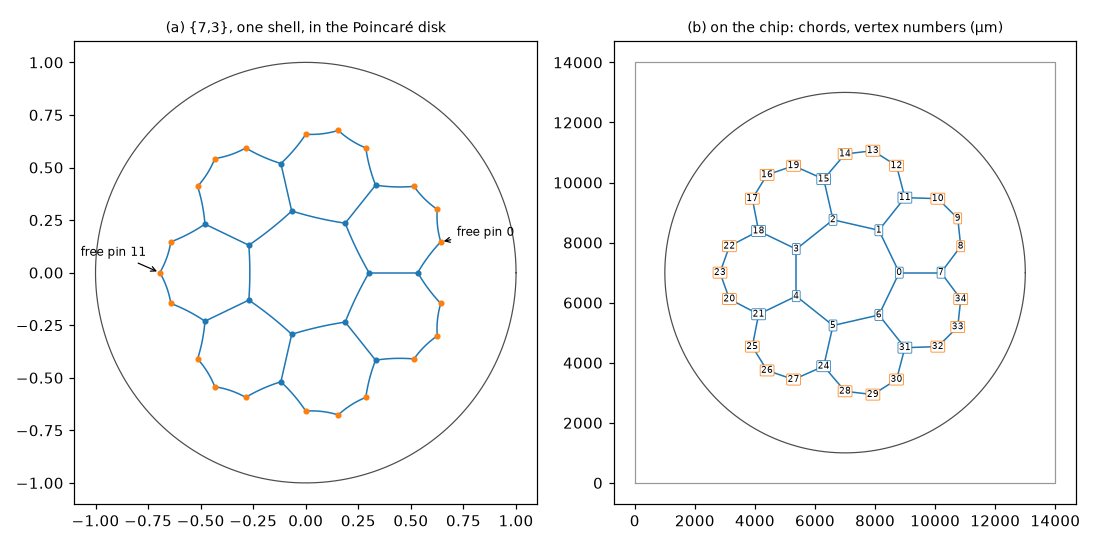

In [6]:
import matplotlib.pyplot as plt


def arc(a, b, n=40):                            # points along the geodesic from a to b
    g = geodesic(a, b)
    if g is None:
        return [a + (b - a) * s / n for s in range(n + 1)]
    c, rho = g
    pa, pb = cmath.phase(a - c), cmath.phase(b - c)
    dp = (pb - pa + math.pi) % (2 * math.pi) - math.pi
    return [c + rho * cmath.exp(1j * (pa + dp * s / n)) for s in range(n + 1)]


fig, (ax, bx) = plt.subplots(1, 2, figsize=(10, 5))
t = np.linspace(0, 2 * np.pi, 400)
ax.plot(np.cos(t), np.sin(t), color="0.3", lw=0.8)
for i, j in edges:
    pts = arc(verts[i], verts[j])
    ax.plot([p.real for p in pts], [p.imag for p in pts], color="C0", lw=1)
for v, z in enumerate(verts):
    ax.plot(z.real, z.imag, "o", ms=3, color="C1" if deg[v] == 2 else "C0")
for n_, (v, k) in ((11, free[11]), (0, free[0])):
    z, dz = verts[v], pin_dir(v, k) * 0.22
    ax.annotate(f"free pin {n_}", (z.real, z.imag), (z.real + dz.real, z.imag + dz.imag + 0.08),
                arrowprops=dict(arrowstyle="->", lw=0.8), fontsize=8, ha="center")
ax.set_aspect("equal")
ax.set_title("(a) {7,3}, one shell, in the Poincaré disk", fontsize=9)
bx.plot(W / 2 + R_DISK * np.cos(t), H / 2 + R_DISK * np.sin(t), color="0.3", lw=0.8)
bx.plot([0, W, W, 0, 0], [0, 0, H, H, 0], color="0.6", lw=0.8)
for i, j in edges:
    bx.plot([cent[i].real, cent[j].real], [cent[i].imag, cent[j].imag], color="C0", lw=1)
for v, z in enumerate(cent):
    bx.text(z.real, z.imag, str(v), fontsize=6, ha="center", va="center",
            bbox=dict(boxstyle="round,pad=0.1", fc="white", ec="C1" if deg[v] == 2 else "C0", lw=0.5))
bx.set_aspect("equal")
bx.set_title("(b) on the chip: chords, vertex numbers (µm)", fontsize=9)
STEPS.mkdir(parents=True, exist_ok=True)
fig.tight_layout()
fig.savefig(STEPS / "tiling.png", dpi=110)
plt.close(fig)
display(Image(filename=str(STEPS / "tiling.png"), width=820))

# Design: the layout, one segment at a time

The chip is built in the order its parts depend on each other: the die, the launchers, the 35 vertex couplers (this
chip has no qubits; the couplers are what every line starts from), the 42 resonators between them, the boundary stubs
on the free pins, and the two probe lines, which start on two free pins and so come after the lattice. Each segment is
one cell with one picture of the chip so far (live, KLayout redraws after every cell). Coordinates are the tiling's ×
6000 µm around the die centre (7000, 7000) µm; nothing is moved afterwards.

| segment | what is placed here |
|---|---|
| 1 | the 14 × 14 mm die with the Quantcore frame (device ID QPDK-HYP) |
| 2 | the two launchers: P1 on the west edge (free pin 11), P2 on the east edge (free pin 0) |
| 3 | no qubits: the 35 vertex couplers `V0` … `V34` at the tiling vertices |
| 4 | the 42 edge resonators `R0` … `R41`, 7500 µm rim to rim, each meandered inside its region |
| 5 | the 19 shorted boundary stubs `S<v>` on the free pins |
| 6 | the coupling: the vertex couplers themselves (nothing to add) |
| 7 | the readout: the two probe lines `F1`, `F2` to the launchers; no control lines |
| 8 | the whole chip: sim groups, the centring check, save |

## Design 1 · The die and its frame

The source frames the lattice's bounding box with a 500 µm margin. Here the die holds the whole 6000 µm-radius disk the
tiling is mapped onto, centred, plus the launchers: **14 × 14 mm**, so the disk ends 1 mm from every die edge and each
launcher (410 µm deep, 100 µm from the edge) sits outside it. The Quantcore die frame and the device ID "QPDK-HYP". No
`with_grid`: the source has no cheese, so the build draws the PDK band.

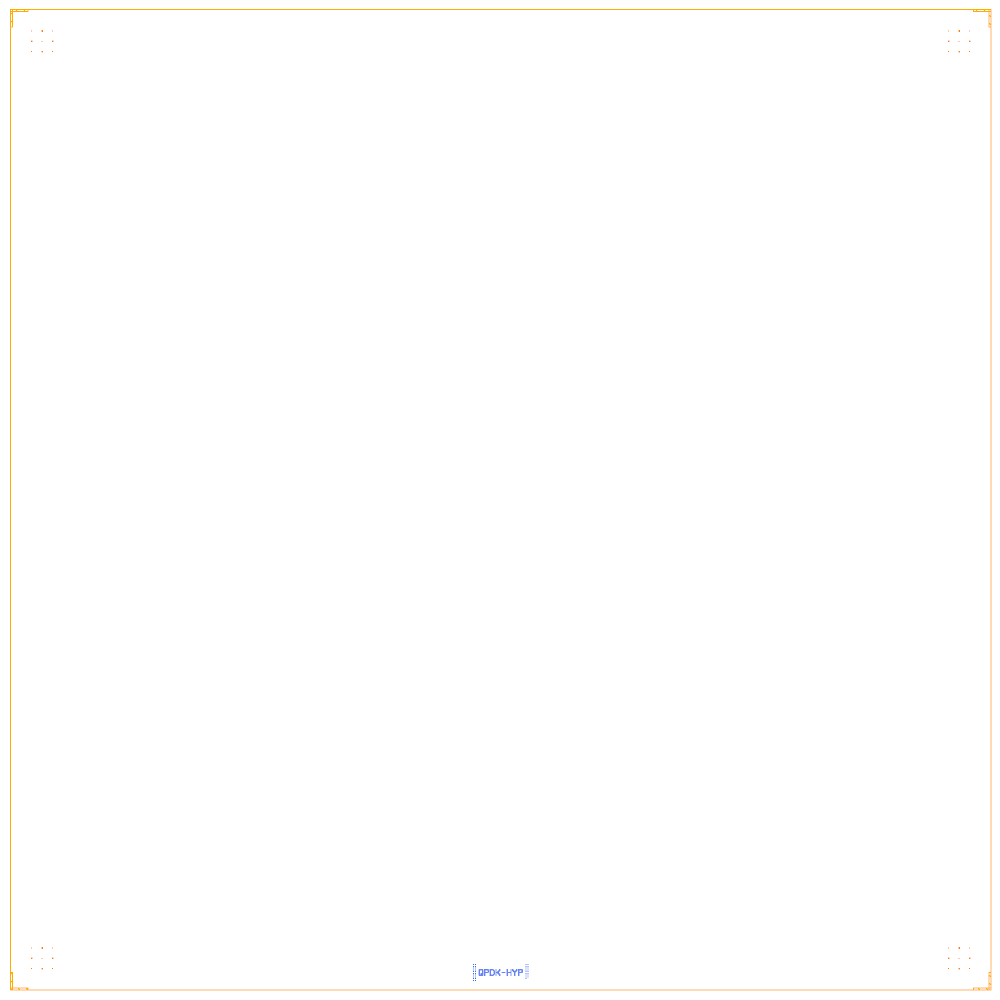

**On the chip so far:** 0 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('build/snapshots/hyperbolic_lattice_chip/s1_die.png')

In [7]:
d = Designer("hyperbolic_lattice_chip", box=(0, 0, W, H), chip={"name_chip": "QPDK-HYP"}, live=LIVE)
layout_step(d, STEPS / "s1_die.png", size=(1000, 1000), width=400)

## Design 2 · Bond pads: the two launchers and the pad rule

QPDK's `launcher` (a 200 × 200 µm wire-bond pad on a 200/110 µm CPW, a 100 µm taper to the 10/6 µm line) is a
KQC-style `BondPad` here (`QP.LAUNCHER`). **PDK rule:** the outer etch edge of a pad sits `frame.pad_edge` (100 µm)
from the die edge; `edge="auto"` in `d.add` applies it. **P1** takes free pin 11 (vertex 23, on the −x axis, pointing
west) on the west edge at the pin's height; **P2** takes free pin 0 (vertex 8, pointing 346.5°) on the east edge at
the height QPDK's feed reaches after 1000 µm along the pin. The first picture is the chip so far, the second zooms on P1.

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| P1 | `BondPad` | w | 100.0 | ✓ |
| P2 | `BondPad` | e | 100.0 | ✓ |

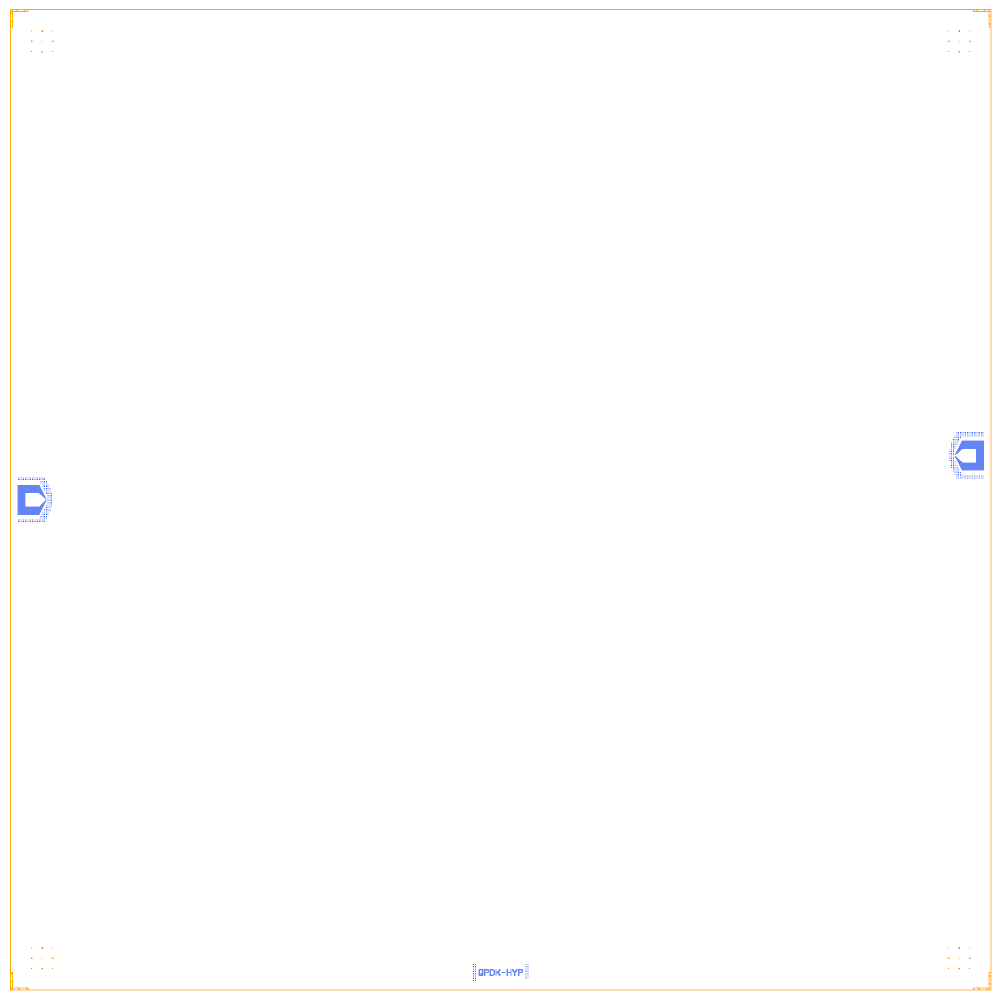

**On the chip so far:** 2 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** 2 component(s) `P1`, `P2`.

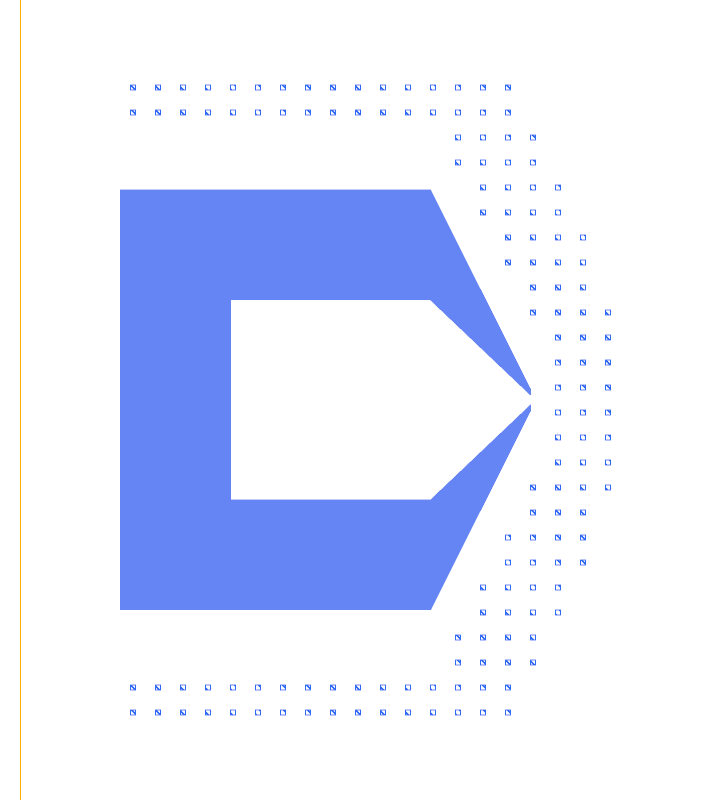

In [8]:
FEED = 1000.0                                    # QPDK feed_length: straight along the probe pin before the turn
(vW, kW), (vE, kE) = free[11], free[0]           # QPDK probe_pins = (11, 0): launcher 1 west, launcher 2 east
PORT_REACH = 40.0 + 20.0                         # pin_radius + lead_length: a coupler port's distance from its centre
corner_E = cent[vE] + (PORT_REACH + FEED) * pin_dir(vE, kE)
with d.batch():
    d.add("P1", "BondPad", at=(QP.LAUNCHER_DEPTH, cent[vW].imag), rot=270, edge="auto", **QP.LAUNCHER)
    d.add("P2", "BondPad", at=(W - QP.LAUNCHER_DEPTH, round(corner_E.imag, 3)), rot=90, edge="auto", **QP.LAUNCHER)
rebuild(d)
display(Markdown(pads_md(d)))
layout_step(d, STEPS / "s2_pads.png", size=(1000, 1000), width=400)
snap(d, STEPS / "2_p1.png", box=(-20, cent[vW].imag - 400, 700, cent[vW].imag + 400), size=(720, 800), width=260);

## Design 3 · No qubits: the 35 vertex couplers

At every vertex a `HyperbolicVertexCoupler` (the library's re-drawing of QPDK's `hyperbolic_vertex_coupler`): a 40 µm
metal disk cut into three pie-slice pins by 4 µm radial gaps, inside a 6 µm ground ring; each pin feeds a 20 µm CPW lead
(10/6 µm) and ends in port `o1`, `o2`, `o3` (pin k along `rotation + 120 k`°). `rotation` is the direction of the
geodesic along the vertex's lowest-numbered edge, so every pin points along its edge's geodesic tangent; on the 21
boundary vertices one pin stays free. This cell is the closest library match: it has exactly the three CPW ports and
the capacitive pin-to-pin gaps the lattice needs, and its LOM model gives the pin–pin and pin–ground capacitances.
The second picture zooms on `V0` (a central vertex).

V0: <HyperbolicVertexCoupler V0 ports=['o1', 'o2', 'o3']> · rotation 120.0 ° · pins [0, 6, 12] (edge on pin k, -1 = free)


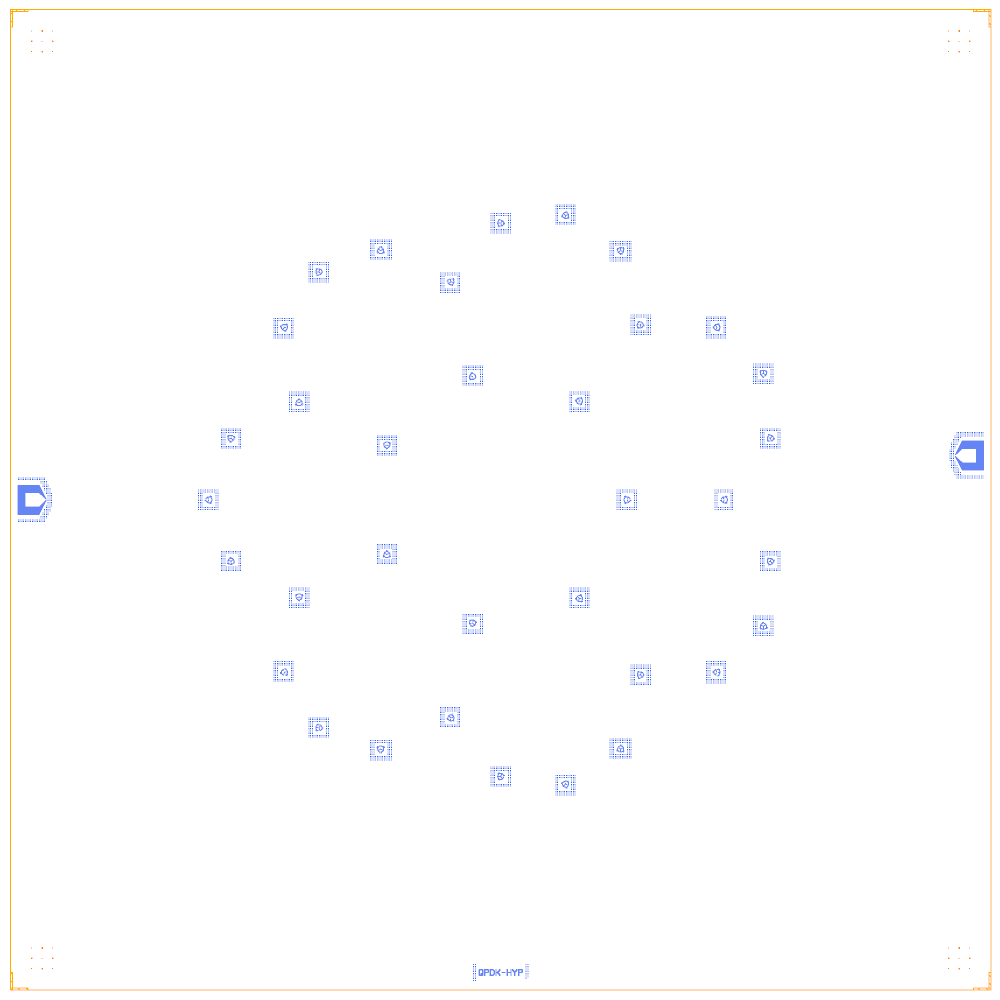

**On the chip so far:** 2 pads · 0 qubits · 35 other components · 0 routes · 0 declared couplings. **This step added** 35 component(s) `V0`, `V1`, `V2`, `V3`, `V4`, `V5`, `V6`, `V7` … (+27).

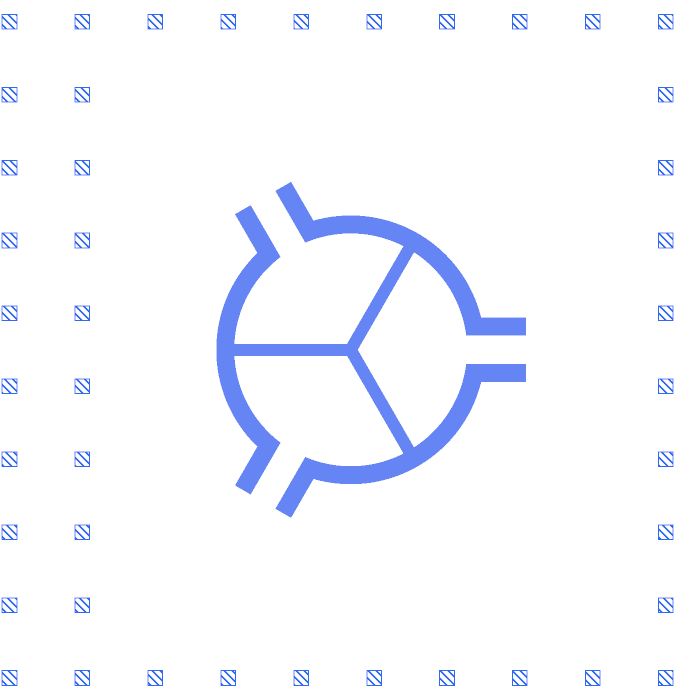

In [9]:
VC = dict(q=3, pin_radius=40, pin_gap=4, ground_gap=6, lead_length=20)   # QPDK hyperbolic_lattice defaults
with d.batch():
    for v, (rot, wiring) in enumerate(pins):
        d.add(f"V{v}", "HyperbolicVertexCoupler", at=xy(cent[v]), rotation=round(rot, 6), **VC)
print("V0:", d["V0"], "· rotation", round(pins[0][0], 3), "° · pins", pins[0][1], "(edge on pin k, -1 = free)")
layout_step(d, STEPS / "s3_couplers.png", size=(1000, 1000), width=400)
x0, y0 = xy(cent[0])
snap(d, STEPS / "3_v0.png", box=(x0 - 120, y0 - 120, x0 + 120, y0 + 120), size=(700, 700), width=300);

## Design 4 · Resonators: the 42 edge resonators

Every edge is one CPW resonator of **7500 µm from pin rim to pin rim**; the two 20 µm leads count, so the route from
port to port is 7460 µm (`L_RES`). As in QPDK, each resonator meanders inside the **region** of its edge: the
quadrilateral of its two vertices and the centroids of the two faces beside it. A boundary edge has one face; its outer
apex is that face's centroid mirrored across the edge and pulled in to 0.6 of the distance. The centreline keeps 25 µm
from the region edge, so two resonators that share a coupler stay 50 µm apart (centre to centre), and resonators that do
not share one are further apart still.

**The serpentine** (computed here): the route leaves each pin straight for 70 µm (`S_END`, QPDK's end straight
2r + 10), then runs legs perpendicular to the line between those two points, alternately up and down, joined by
U-turns of radius r = 30 µm at a pitch of at least 62 µm (QPDK: exactly 2r = 60 µm; the 2 µm spare keeps the two bends of
a U-turn inside the router's bend check). Each U-turn's height is the region's room at both of its ends, capped by one
common height H, and H is solved so the drawn length (straights minus what each bend cuts, 2r − πr/2 per 90° turn) is
2 µm short of `L_RES`. `d.route(..., nodes=..., r=30, meander=L_RES)` draws it through those nodes and closes the last
µm by trimming the corner radii (by under 5 %), so every resonator is 7460 µm as built. The table sums it up per kind of
edge; the second picture zooms on the central resonator `R0` between `V0` and `V1`.

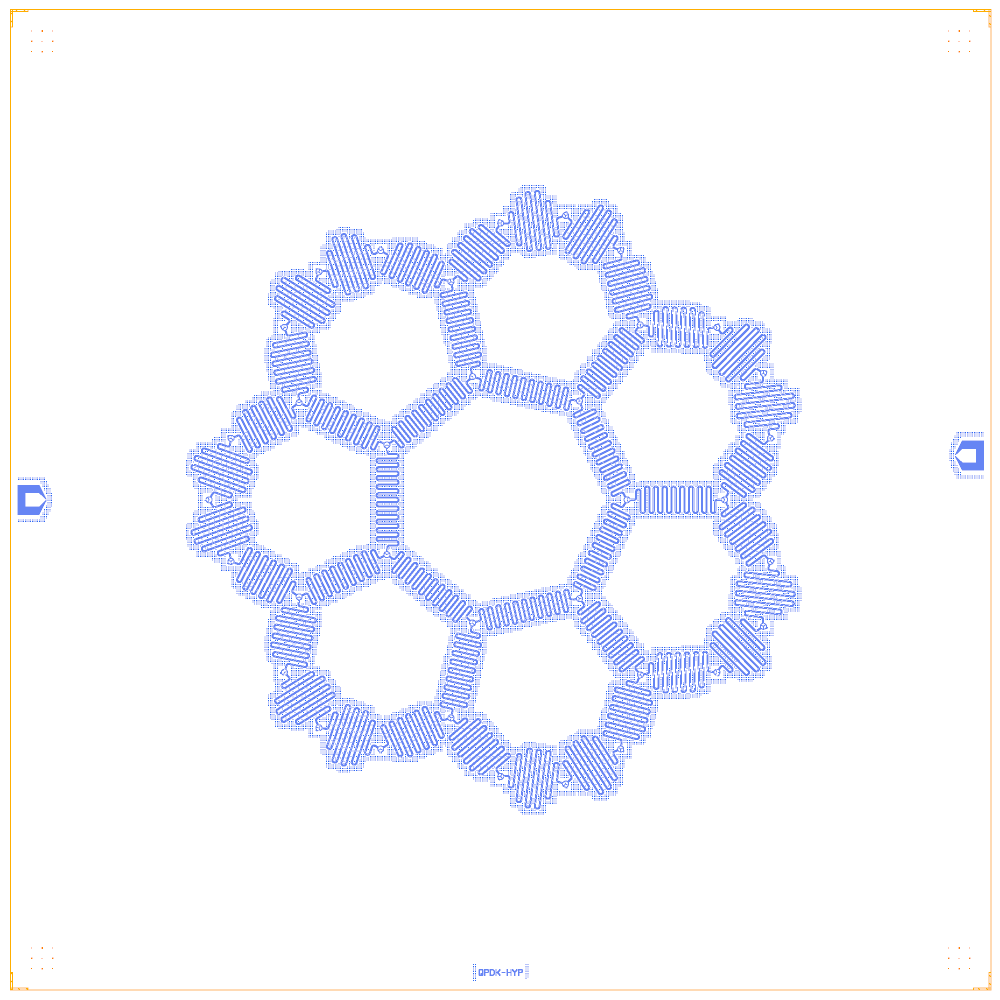

**On the chip so far:** 2 pads · 0 qubits · 35 other components · 42 routes · 0 declared couplings. **This step added** 42 route(s) `R0`, `R1`, `R2`, `R3`, `R4`, `R5`, `R6`, `R7` … (+34).

| edges | count | chord (µm) | U-turns | pitch (µm) | height H (µm) | built length (µm) |
|---|---|---|---|---|---|---|
| central (e.g. `R0`, V0–V1) | 7 | 1566 | 21 | 62.2 | 157 | 7459.995 – 7460.006 |
| radial (e.g. `R11`, V1–V11) | 7 | 1390 | 18 | 62.8 | 188 | 7459.992 – 7460.012 |
| outer (e.g. `R7`, V7–V8) | 14 | 1097 | 13 | 64.5 | 282 | 7459.990 – 7460.009 |
| rim (e.g. `R8`, V8–V9) | 14 | 933 | 10 | 67.7 | 419 | 7459.996 – 7460.004 |

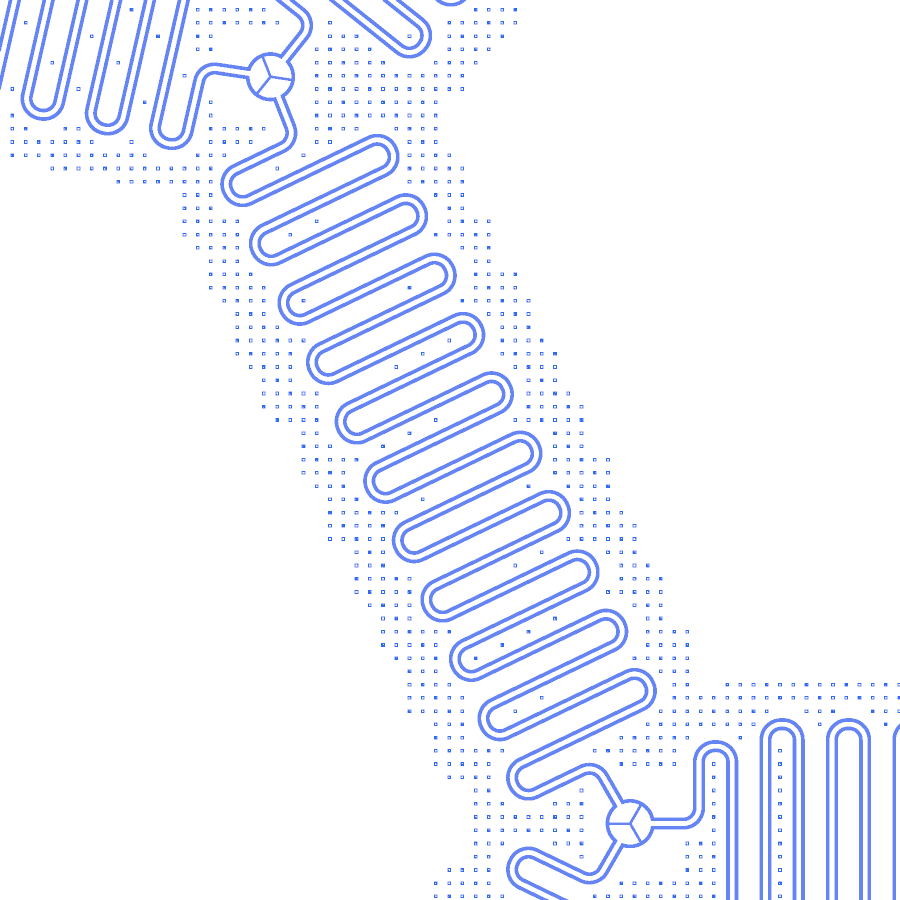

In [10]:
R_B, S_END, MARGIN, APEX = 30.0, 70.0, 25.0, 0.6    # bend radius, end straight, region margin, boundary apex pull-in
L_RES = 7500.0 - 2 * VC["lead_length"]              # port to port: the 7500 µm include both leads
PITCH_MIN = 2 * R_B + 2                             # legs at least 62 µm apart
face_c = [sum(cent[v] for v in f) / len(f) for f in faces]
edge_faces = {e: [n for n, f in enumerate(faces) if any({f[k], f[(k + 1) % P_]} == set(ij) for k in range(P_))]
              for e, ij in enumerate(edges)}


def region(e):
    # the quadrilateral vertex, face centroid, vertex, face centroid (outer apex of a boundary edge: mirrored × APEX)
    i, j = edges[e]
    apexes = [face_c[f] for f in edge_faces[e]]
    if len(apexes) == 1:
        mid, n = (cent[i] + cent[j]) / 2, 1j * (cent[j] - cent[i]) / abs(cent[j] - cent[i])
        apexes.append(mid - n * APEX * ((apexes[0] - mid) * n.conjugate()).real)
    return [cent[i], apexes[0], cent[j], apexes[1]]


def shrink(poly, m):
    # a convex polygon moved in by m on every side
    if sum((a.conjugate() * b).imag for a, b in zip(poly, poly[1:] + poly[:1])) < 0:
        poly = poly[::-1]
    lines = [(a + 1j * (b - a) / abs(b - a) * m, (b - a) / abs(b - a)) for a, b in zip(poly, poly[1:] + poly[:1])]
    out = []
    for (p1, t1), (p2, t2) in zip(lines[-1:] + lines[:-1], lines):
        out.append(p1 + t1 * ((p2 - p1).conjugate() * t2).imag / (t1.conjugate() * t2).imag)
    return out


def room(poly, x, side):
    # how far the convex polygon reaches from the axis at abscissa x, upwards (side +1) or downwards (-1)
    ys = [a.imag + (b.imag - a.imag) * (x - a.real) / (b.real - a.real) for a, b in zip(poly, poly[1:] + poly[:1])
          if (a.real - x) * (b.real - x) <= 0 and abs(b.real - a.real) > 1e-12]
    return (max(ys) if side > 0 else -min(ys)) if ys else -1.0


def bend_cut(theta):                                # length a bend of angle theta (radius R_B) takes off the polyline
    return (2 * math.tan(theta / 2) - theta) * R_B


def serpentine(e, length=L_RES, short=2.0):
    # nodes of edge e's meander and (turns, pitch, common height); its drawn length is `length - short`
    i, j = edges[e]
    ki, kj = pins[i][1].index(e), pins[j][1].index(e)
    di, dj = pin_dir(i, ki), pin_dir(j, kj)
    ai, aj = cent[i] + (PORT_REACH + S_END) * di, cent[j] + (PORT_REACH + S_END) * dj
    span, u = abs(aj - ai), (aj - ai) / abs(aj - ai)
    reg = [(z - ai) / u for z in shrink(region(e), MARGIN)]       # in the frame of the axis ai → aj
    n = int(span // PITCH_MIN)
    p = span / n
    best = None
    for first in (1, -1):                            # first leg up or down: the side with more room wins
        sides = [first * (-1) ** k for k in range(n)]
        caps = [min(room(reg, k * p, s), room(reg, (k + 1) * p, s)) for k, s in enumerate(sides)]
        th_i = math.acos(max(-1.0, min(1.0, (di.conjugate() * sides[0] * 1j * u).real)))
        th_j = math.acos(max(-1.0, min(1.0, ((-sides[-1] * 1j * u).conjugate() * -dj).real)))

        def drawn(h, caps=caps, th_i=th_i, th_j=th_j):
            return 2 * S_END + n * p + 2 * sum(min(c, h) for c in caps) - 2 * n * bend_cut(math.pi / 2) \
                - bend_cut(th_i) - bend_cut(th_j)
        if best is None or drawn(1e9) > best[0]:
            best = (drawn(1e9), sides, caps, drawn)
    most, sides, caps, drawn = best
    assert most >= length - short, f"R{e}: the region holds {most:.0f} µm, less than {length - short:.0f} µm"
    lo, hi = 0.0, max(caps)
    for _ in range(60):                              # the common height H, by bisection
        lo, hi = (lo, (lo + hi) / 2) if drawn((lo + hi) / 2) >= length - short else ((lo + hi) / 2, hi)
    hts = [min(c, hi) for c in caps]
    assert min(hts) >= 2 * R_B + 10, f"R{e}: a U-turn only {min(hts):.0f} µm from the axis"
    nodes = [ai] + [ai + u * complex(x, s * h) for k, (s, h) in enumerate(zip(sides, hts)) for x in (k * p, (k + 1) * p)]
    return [xy(z) for z in nodes + [aj]], n, p, hi


def kind(e):
    i, j = edges[e]
    return ("central" if max(i, j) < P_ else "radial" if min(i, j) < P_
            else "rim" if deg[i] == deg[j] == 2 else "outer")


plan = {}
with d.batch():
    for e, (i, j) in enumerate(edges):
        nodes, n, p, h = serpentine(e)
        plan[e] = (n, p, h)
        d.route(f"R{e}", f"V{i}.o{pins[i][1].index(e) + 1}", f"V{j}.o{pins[j][1].index(e) + 1}",
                meander=L_RES, r=R_B, nodes=nodes)
layout_step(d, STEPS / "s4_resonators.png", size=(1000, 1000), width=400)
lengths = d.result.route_lengths()
rows = ["| edges | count | chord (µm) | U-turns | pitch (µm) | height H (µm) | built length (µm) |", "|---|---|---|---|---|---|---|"]
for name in ("central", "radial", "outer", "rim"):
    es = [e for e in plan if kind(e) == name]
    ls = [lengths[f"R{e}"] for e in es]
    i, j = edges[es[0]]
    rows.append(f"| {name} (e.g. `R{es[0]}`, V{i}–V{j}) | {len(es)} | {abs(cent[j] - cent[i]):.0f} | {plan[es[0]][0]} | "
                f"{plan[es[0]][1]:.1f} | {plan[es[0]][2]:.0f} | {min(ls):.3f} – {max(ls):.3f} |")
display(Markdown("\n".join(rows)))
mid = (cent[0] + cent[1]) / 2
snap(d, STEPS / "4_r0.png", box=(mid.real - 850, mid.imag - 850, mid.real + 850, mid.imag + 850), size=(900, 900), width=380);

## Design 5 · The 19 boundary stubs

Each free pin on the boundary that is not a probe gets QPDK's **shorted stub**: a straight CPW along the pin, 400 µm
from the pin rim to the short (380 µm beyond the port), ending on ground (`Designer.free_end(..., term=0)`). A λ/4 of
400 µm resonates far above the band (≈ 60 GHz here); near 8 GHz it is close to a short, so the boundary resonators see
about the same end loading at a free pin as at a pin shared with another resonator. The second picture zooms on vertex 9
on the rim, its stub between two rim resonators.

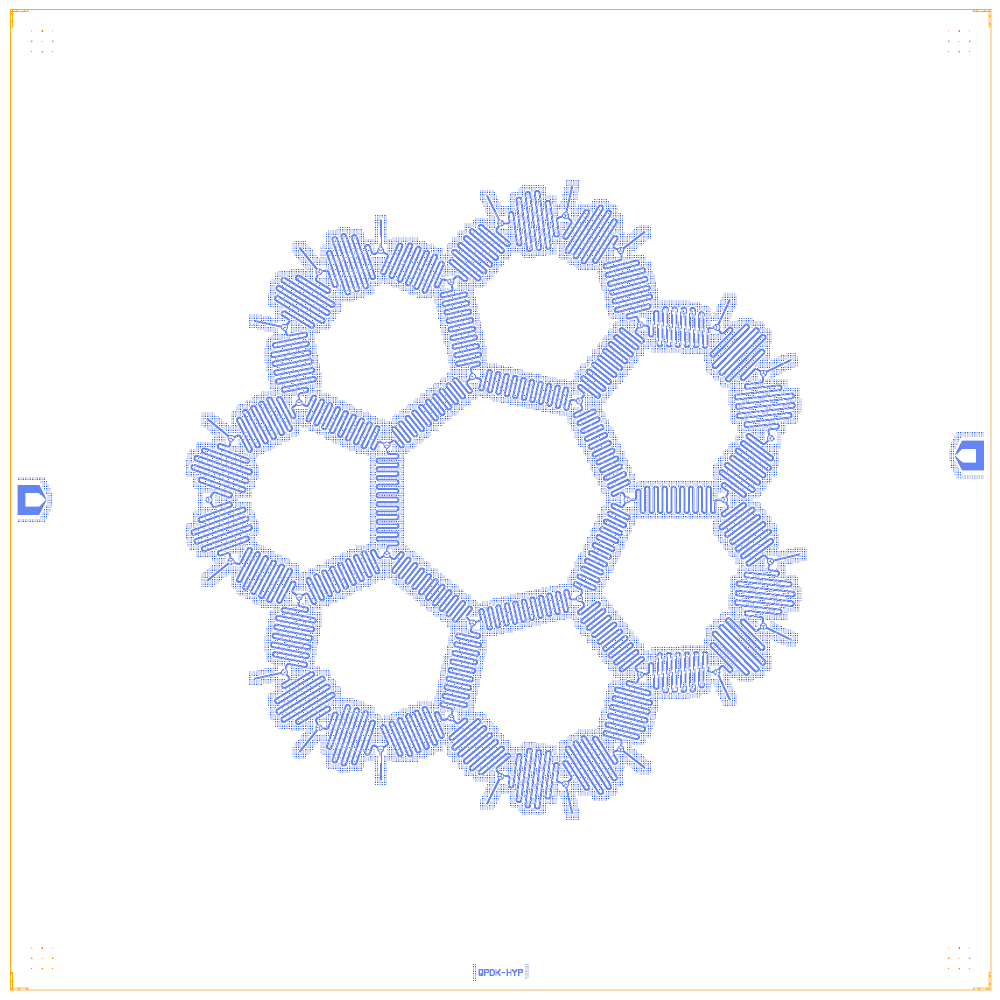

**On the chip so far:** 2 pads · 0 qubits · 35 other components · 61 routes · 0 declared couplings. **This step added** 19 route(s) `S9`, `S10`, `S12`, `S13`, `S14`, `S16`, `S17`, `S19` … (+11).

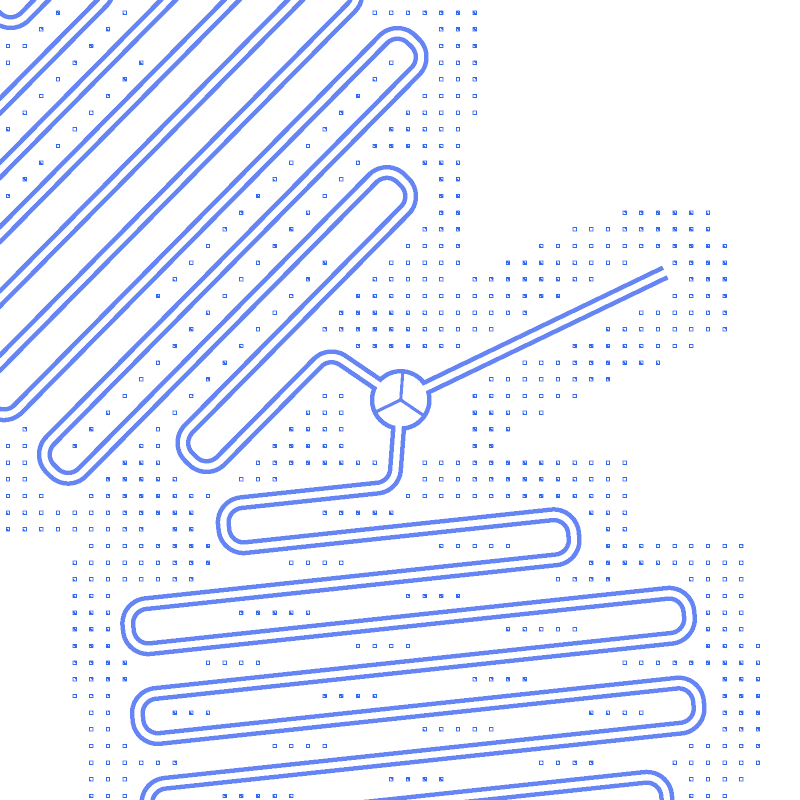

In [11]:
STUB = 400.0 - VC["lead_length"]                 # port to short: 400 µm from the pin rim
with d.batch():
    for n_, (v, k) in enumerate(free):
        if n_ in (0, 11):                        # the probe pins (Design 7)
            continue
        ang = pins[v][0] + 360 * k / Q_
        tip = cent[v] + (PORT_REACH + STUB) * unit(ang)
        d.route(f"S{v}", f"V{v}.o{k + 1}", Designer.free_end(xy(tip), dir=round((ang + 180) % 360, 6), term=0), r=R_B)
layout_step(d, STEPS / "s5_stubs.png", size=(1000, 1000), width=400)
x9, y9 = xy(cent[9])
snap(d, STEPS / "5_v9.png", box=(x9 - 600, y9 - 600, x9 + 600, y9 + 600), size=(800, 800), width=340);

## Design 6 · Coupling: the vertex couplers

The resonators couple only through the vertex couplers placed in Design 3: at each vertex the three pins face each other
across the 4 µm radial gaps, so the three resonator ends that meet there share a capacitance network (pin to pin, pin to
ground). That is the whole lattice: nothing else couples on purpose, and no `d.couple` is needed (the coupler's LOM model
carries the capacitances).

## Design 7 · Readout: the two probe lines

**F1** runs from free pin 11 (vertex 23) straight west to P1: the pin already points along −x, so it is QPDK's feed
without a turn, only longer (the launcher sits on the pad rule). **F2** runs from free pin 0 (vertex 8) 1000 µm along the
pin (346.5°), as QPDK's feed does, then turns by 13.5° onto the +x axis and runs east to P2. Bend radius 100 µm
(QPDK's `cpw`). No flux, drive or charge lines: the chip has no qubits.

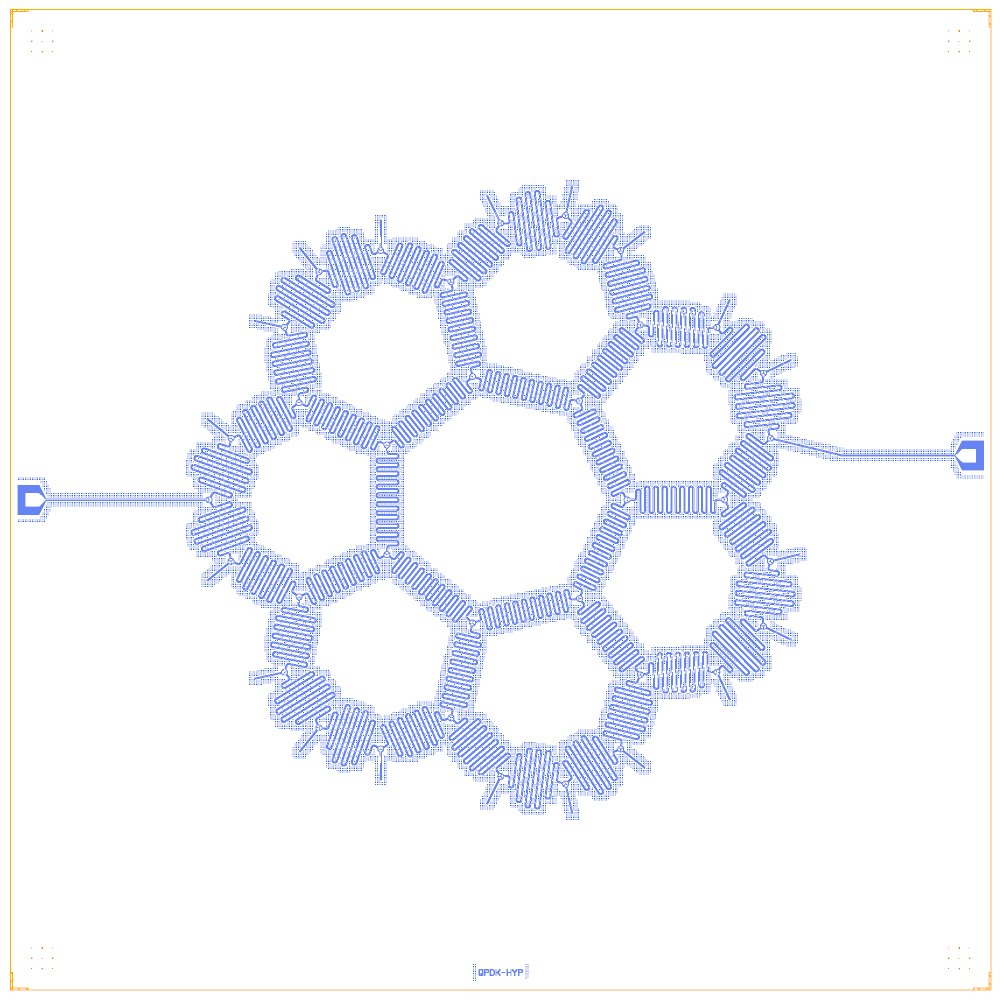

**On the chip so far:** 2 pads · 0 qubits · 35 other components · 63 routes · 0 declared couplings. **This step added** 2 route(s) `F1`, `F2`.

{'S9': 380.0, 'F1': 2266.1, 'F2': 2608.5}


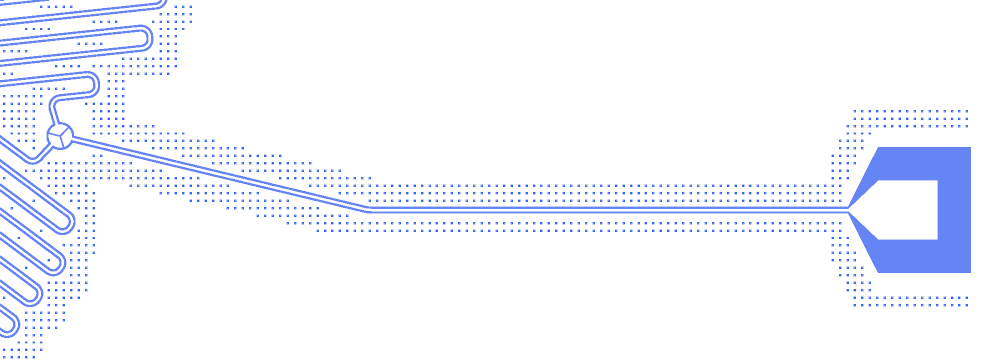

In [12]:
with d.batch():
    d.route("F1", f"V{vW}.o{kW + 1}", "P1.a", r=QP.CPW_R)
    d.route("F2", f"V{vE}.o{kE + 1}", "P2.a", nodes=[xy(corner_E)], r=QP.CPW_R)
layout_step(d, STEPS / "s7_probes.png", size=(1000, 1000), width=400)
print({k: round(v, 1) for k, v in d.result.route_lengths().items() if k in ("F1", "F2", "S9")})
snap(d, STEPS / "7_f2.png", box=(cent[vE].real - 200, corner_E.imag - 500, W, corner_E.imag + 700), size=(1000, 360), width=520);

## Design 8 · The whole chip: sim groups, the centring, save

**Sim groups** say what a FEM job cuts out of the chip. The whole lattice (42 resonators of 7.5 mm on a 9 mm flake) is
beyond one FEM job, so the groups are the two pieces that set the lattice's numbers: **`V0`**, the central coupler alone
(Q3D C-matrix, 100 µm margin: the pin–pin and pin–ground capacitances that set the hopping), and **`R0`**, one central
resonator with its two couplers (eigenmode, 150 µm margin: the loaded resonator frequency; the box cuts the neighbouring
resonators into 50 Ω ports).

**Centring.** The source centres the lattice on its disk, and the die here is centred on the disk, so nothing is moved.
The flake is symmetric about the x axis but not in x (a heptagon with a corner on +x); the content box that
`pdk_report` measures (Check 1) includes the two launchers, one on each side edge 100 µm in, so it is centred anyway.

**Save.** `save_design` writes `hyperbolic_lattice_chip.json` and compares it with the file it replaces (the previous
run's): it says *same design* when the build has not changed.

content box 13800 × 8977 µm, centre − die centre (+0, -0) µm (not shifted: the disk is centred)


**Same design as before:** `examples/designs/qpdk/hyperbolic_lattice_chip.json` is identical to the file it replaces (byte for byte). The segments changed how the chip is built, not the chip.

<Designer hyperbolic_lattice_chip: 37 instances, 63 routes, live=False> → examples\designs\qpdk\hyperbolic_lattice_chip.json


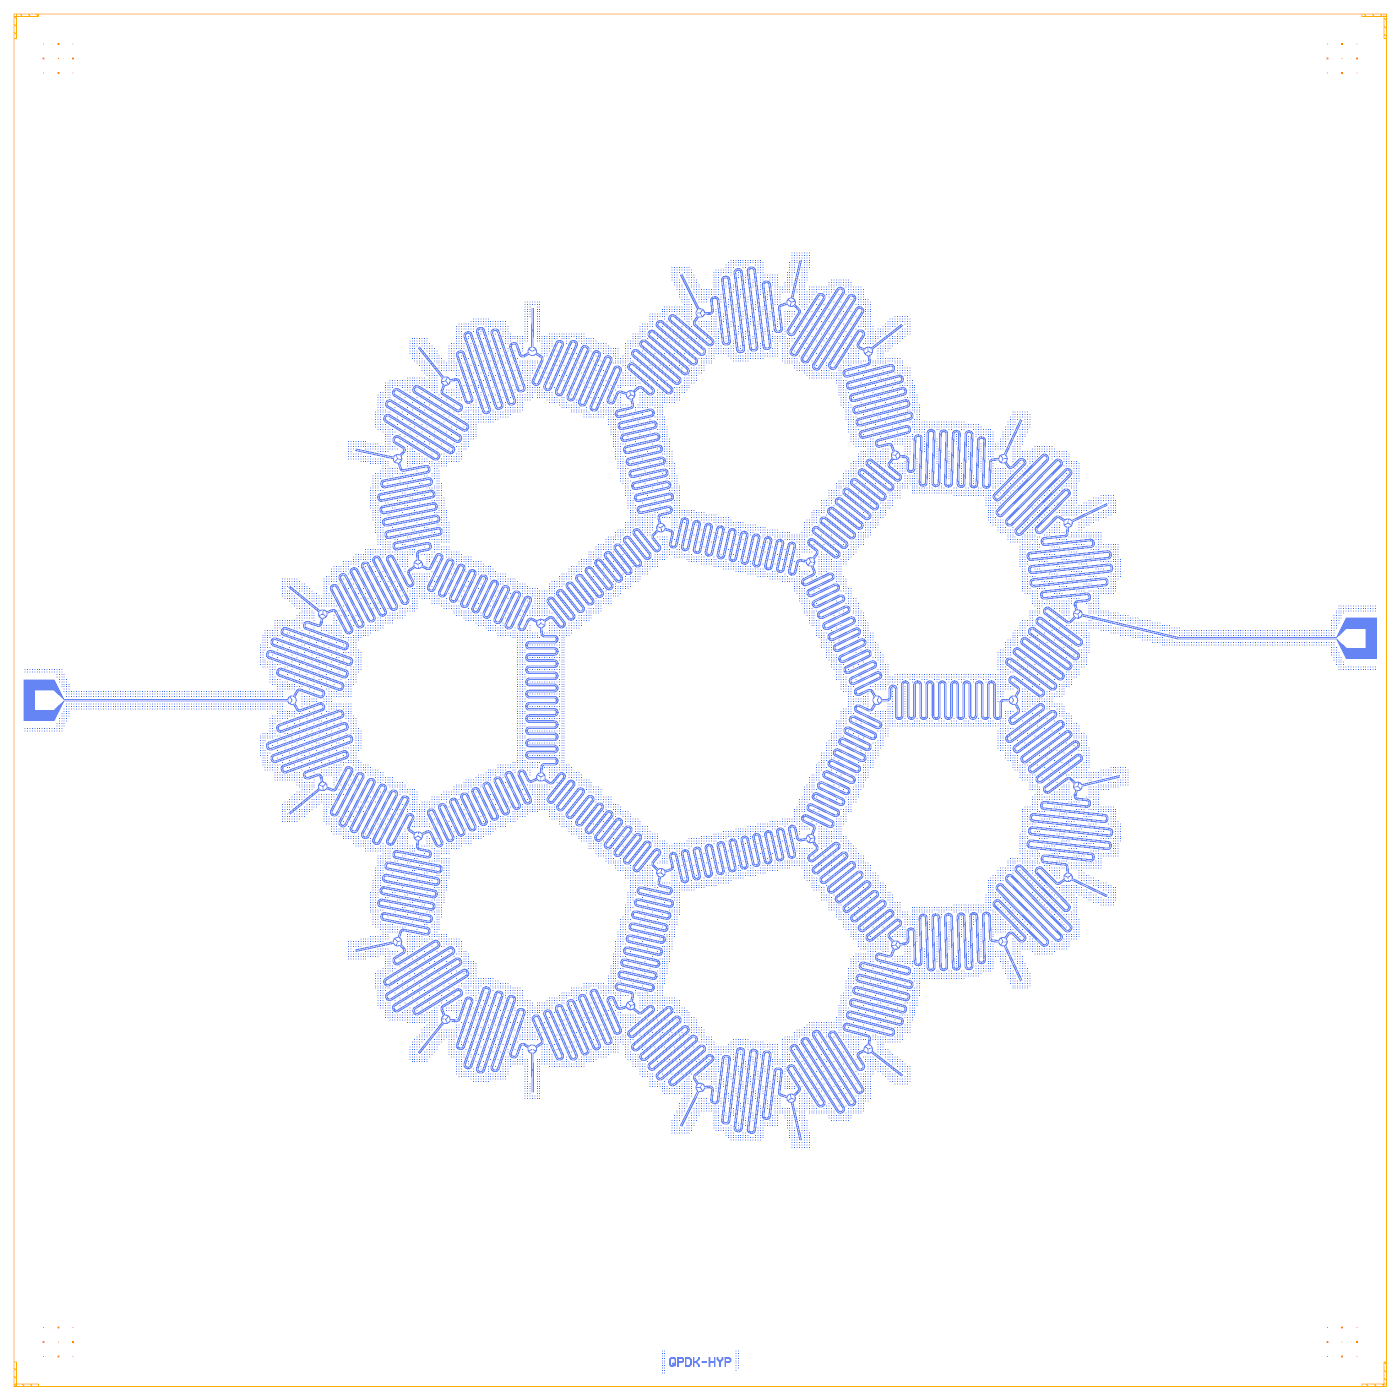

**On the chip so far:** 2 pads · 0 qubits · 35 other components · 63 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('build/snapshots/hyperbolic_lattice_chip/s8_chip.png')

In [13]:
d.sim_group("V0", ["V0"], margin_um=100, analyses=["q3d_cmatrix"])
d.sim_group("R0", ["V0", "V1", "R0"], margin_um=150, analyses=["eigenmode_epr"])
rebuild(d)
box = content_box(d)
print(f"content box {box.width():.0f} × {box.height():.0f} µm, centre − die centre ({box.center().x - W / 2:+.0f}, "
      f"{box.center().y - H / 2:+.0f}) µm (not shifted: the disk is centred)")
DESIGN, same = save_design(d, OUT / "hyperbolic_lattice_chip.json")
display(Markdown(same))
print(d, "→", DESIGN)
layout_step(d, STEPS / "s8_chip.png", size=(1400, 1400), width=560)

# Check: DRC and netlist

The plugin's *Check* step: the design rules, then the lumped circuit the layout turns into.

## Check 1 · DRC

The DRC reports three kinds of issue. **Errors** (overlaps, crossings without a bridge, unconnected ends, metal outside
the die) make the build unfit for fab. **Warnings** are connectivity or geometry notes to read. **PDK design warnings**
flag values outside the PDK margins (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`): flagged, never enforced; the rebuild
keeps the source's choices. `pdk_report` adds the cheese source, the centring (of everything, pads included) and the
junction types. Expected here: no errors, no warnings (every pin is wired: 42 resonators, 19 stubs, 2 probe lines) and
no PDK design warnings (both pads 100 µm from the edge, no junctions). Resonators that share a coupler are not checked
against each other by the route-overlap rule; their 50 µm spacing comes from the regions (Design 4).

In [ ]:
display(Markdown(drc_md(d.drc())))
display(Markdown(pdk_report(d)))

## Check 2 · Netlist

`d.lom()` turns the layout into a lumped circuit. Each coupler pin is a node; a meandered route between two ports is a
λ/2 resonator (`TLres`, open at both ends) whose two end nodes join into one resonator node, so each of the 42
resonators is one node and each vertex coupler is a capacitance network between the (up to) three resonators that meet
there: C between neighbouring pins across the 4 µm gaps, C from each pin to ground. A stub is a λ/4 `TLres` (shorted) on
its free pin, a probe pin is a 50 Ω port (the pad). The full list has 273 branches; the table shows the counts and the
branches at the central vertex `V0`, resonator `R0`, one stub and one port.

In [ ]:
from collections import Counter

lb = d.lom()
m = lb.model


def value_md(b):
    v = b.value or {}
    if b.type == "C":
        return f"{v.get('estimate', '–')} fF ({v.get('estimate_source', '')})"
    if b.type == "TLres":
        return f"{v['kind']}, {v['length_um']:.1f} µm, {v['f_GHz']:.4f} GHz, Z0 {v['Z0_ohm']:.1f} Ω"
    if b.type == "R":
        return f"{v.get('R_ohm', 50):g} Ω"
    return "–"


display(Markdown(
    f"**{sum(1 for s in m.nodes.values() if not s.ground)} nodes (+ ground) · {len(m.branches)} branches** ("
    + ", ".join(f"{n} {t}" for t, n in Counter(b.type for b in m.branches.values()).items())
    + f") · {len(m.controls)} controls · unconnected ports: {', '.join(lb.unconnected) or 'none'}\n\n"
    "| branch | type | nodes | value |\n|---|---|---|---|\n" + "\n".join(
        f"| `{n}` | {b.type} | `{b.nodes[0]}` – `{b.nodes[1]}` | {value_md(b)} |" for n, b in m.branches.items()
        if n.startswith("C_V0_") or n in ("R0", "S9", "Port_P2"))))
print("TLres lengths of the 42 resonators (µm):", sorted({round(m.branches[f"R{e}"].value["length_um"], 2) for e in range(len(edges))}))

# LOM: simulate the lumped circuit, and plot it

## LOM 1 · The LOM simulation

**The resonators.** All 42 have the same length, so the same bare frequency: the λ/2 of 7460 µm on sapphire (the
`TLres` value in Check 2). Loaded by its two couplers each one sits a little lower. `simulate_groups` (QuCat normal
modes) runs one resonator with its two couplers per kind of edge: a central and a radial one (their couplers' other pins
float in this cut), an outer and a rim one with their stubs, and the two next to the east probe (with F2 and P2, so the
mode gets a κ into the 50 Ω port).

**The lattice.** QuCat cannot solve the whole lattice: the flake's sevenfold symmetry makes most modes come in
degenerate pairs, and QuCat's root search finds none of them (on the central heptagon alone it returns no mode and
`simulate` stops; on the whole lattice it does not finish in ten minutes). So the notebook solves the same LOM circuit
(`d.lom()` + `fill`, the component estimates) as a lossless normal-mode problem, K v = ω² C v: each C between its
nodes, each `TLres` as the parallel LC of its fundamental (C = π/(2ωZ₀) for λ/2, π/(4ωZ₀) for λ/4, L = 1/(ω²C), as
`simulate` maps it), the two 50 Ω ports as shorts (next to a pin's ≈ 800 Ω reactance at 8 GHz), and the nodes without
an inductor removed exactly by Kron reduction. Each mode is labelled by the element that holds most of its inductive
energy.

In [ ]:
import scipy.linalg
from quantcore_circuits.circuit.fill import fill



def group(e):
    # resonator e with its two couplers and whatever sits on their free pins (a stub, or a probe line and its pad)
    i, j = edges[e]
    sel = [f"V{i}", f"V{j}", f"R{e}"]
    for v in (i, j):
        sel += ["F1", "P1"] if v == vW else ["F2", "P2"] if v == vE else [f"S{v}"] if deg[v] == 2 else []
    return sel


probe_edges = at_vertex[vE]                      # the two resonators at the east probe pin
reps = [next(e for e in range(len(edges)) if kind(e) == k_ and e not in probe_edges and vW not in edges[e])
        for k_ in ("central", "radial", "outer", "rim")] + probe_edges
GROUPS = {f"R{e}": group(e) for e in reps}
res = simulate_groups(d, GROUPS, max_modes=1)
f_bare = m.branches["R0"].value["f_GHz"]
rows = ["| group | edge | f_r (GHz) | κ (MHz) | other modes |", "|---|---|---|---|---|"]
for g, r in res.items():
    mode = next(md_ for md_ in r.modes if md_.label == g)
    rest = ", ".join(f"{md_.label} {md_.f_GHz:.1f} GHz" for md_ in r.modes if md_.label != g) or "–"
    kap = "–" if mode.kappa_MHz is None else f"{mode.kappa_MHz:.3g}"
    rows.append(f"| {g} | {kind(int(g[1:]))} | {mode.f_GHz:.4f} | {kap} | {rest} |")
display(Markdown(f"**Bare λ/2 of every resonator: {f_bare:.4f} GHz** (7460 µm). One resonator with its two couplers:\n\n"
                 + "\n".join(rows)))


def lattice_modes(dd):
    # lossless normal modes of the LOM circuit of `dd` (a Designer): [(f GHz, label)], lowest first
    filled = fill(dd.lom().model, dd.design)
    gnd = filled.model.ground
    shorted = {n for v in filled.values.values() if v.type == "R" for n in v.nodes} - {gnd}   # 50 Ω ports ≈ ground
    nodes = [n for n in filled.model.nodes if n != gnd and n not in shorted]
    ix = {n: k for k, n in enumerate(nodes)}
    cm, km = np.zeros((len(nodes), len(nodes))), np.zeros((len(nodes), len(nodes)))

    def stamp(mat, a, b, y):
        for p_, q_, s in ((a, a, 1), (b, b, 1), (a, b, -1), (b, a, -1)):
            if p_ in ix and q_ in ix:
                mat[ix[p_], ix[q_]] += s * y
    on = {}
    for name, v in filled.values.items():
        if v.type == "C" and v.value:
            stamp(cm, *v.nodes, v.value * 1e-15)
        elif v.type == "TL":
            w = 2 * math.pi * v.extra["f_GHz"] * 1e9
            c = math.pi / ((2 if v.extra.get("kind") == "lambda/2" else 4) * w * v.extra["Z0_ohm"])
            stamp(cm, *v.nodes, c)
            stamp(km, *v.nodes, w * w * c)        # 1/L = ω² C
            on[name] = ix[next(n for n in v.nodes if n != gnd)]
    keep = sorted(set(on.values()))
    drop = [k for k in range(len(nodes)) if k not in keep]
    c_red = cm[np.ix_(keep, keep)]
    if drop:                                     # capacitor-only nodes carry no charge in a mode: Kron reduction
        c_red = c_red - cm[np.ix_(keep, drop)] @ np.linalg.solve(cm[np.ix_(drop, drop)], cm[np.ix_(drop, keep)])
    w2, vec = scipy.linalg.eigh(km[np.ix_(keep, keep)], c_red)
    inv_l = {name: km[k, k] for name, k in on.items()}
    out = []
    for col, lam in zip(vec.T, w2):
        energy = {name: col[keep.index(k)] ** 2 * inv_l[name] for name, k in on.items()}
        out.append((math.sqrt(lam) / (2 * math.pi * 1e9), max(energy, key=energy.get)))
    return out


B = np.zeros((len(verts), len(edges)))           # vertex-edge incidence; line graph adjacency A_L = BᵀB - 2I
for e, (i, j) in enumerate(edges):
    B[i, e] = B[j, e] = 1
lam = np.sort(np.linalg.eigvalsh(B.T @ B - 2 * np.eye(len(edges))))


def band(modes):
    # the 42 lattice modes, the tight-binding fit f = f0 + t λ on the line graph, and the stub modes
    f = np.array(sorted(fq for fq, lab in modes if lab.startswith("R")))
    assert len(f) == len(edges), f"{len(f)} resonator modes for {len(edges)} resonators"
    t_, f0 = np.polyfit(lam, f, 1)
    return {"f": f, "f0": f0, "t": t_, "rms": float(np.sqrt(np.mean((f - f0 - t_ * lam) ** 2))),
            "flat": f[:7], "stubs": sorted(fq for fq, lab in modes if lab.startswith("S"))}


lat = band(lattice_modes(d))
n_flat = int(np.sum(np.isclose(lam, -2)))
display(Markdown(
    f"**The lattice (42 resonator modes).** Line graph: {n_flat} eigenvalues at −2 (E − V = 42 − 35: the flat band), "
    f"the rest from {lam[n_flat]:.3f} to {lam[-1]:.3f}. LOM modes {lat['f'][0]:.4f} – {lat['f'][-1]:.4f} GHz; the "
    f"tight-binding fit f = f₀ + t·λ gives **f₀ = {lat['f0']:.4f} GHz, t = {1e3 * lat['t']:.1f} MHz** "
    f"(rms residual {1e3 * lat['rms']:.1f} MHz). **Flat band:** the {n_flat} lowest modes at "
    f"{lat['flat'].mean():.4f} GHz (spread {1e6 * np.ptp(lat['flat']):.0f} kHz), f₀ − 2t = {lat['f0'] - 2 * lat['t']:.4f} GHz. "
    f"The 19 stub modes sit at {min(lat['stubs']):.1f} – {max(lat['stubs']):.1f} GHz.\n\n"
    "| | | | | | | |\n|---|---|---|---|---|---|---|\n" + "\n".join(
        "| " + " | ".join(f"{x:.4f}" for x in lat["f"][r:r + 7]) + " |" for r in range(0, 42, 7))))

## LOM 2 · The LOM in plots

First the one-resonator groups (QuCat; squares are resonators; the stub modes near 60 GHz are left out), then the
lattice: (a) the 42 modes in order against the tight-binding band f₀ + t·λₙ of the line graph (t > 0 in this form),
(b) their density of states. The flat band (λ = −2, seven modes) sits at the bottom, at f₀ − 2t: QPDK's "flat band
at ω₀ − 2|t|".

In [ ]:
import copy

below = {}
for g, r in res.items():                         # the stub modes (≈ 60 GHz) left out of the plot
    below[g] = copy.copy(r)
    below[g].modes = [md_ for md_ in r.modes if md_.f_GHz < 20]
plot_lom(below, STEPS / "lom_groups.png", title="hyperbolic_lattice_chip: one resonator with its couplers per group")
c = plt.rcParams["axes.prop_cycle"].by_key()["color"]
fig, (ax, bx) = plt.subplots(1, 2, figsize=(10, 3.8), gridspec_kw={"width_ratios": [3, 2]})
k = np.arange(1, 43)
ax.plot(k, lat["f0"] + lat["t"] * lam, "-", color="0.6", lw=1, label=f"f₀ + t·λₙ (f₀ {lat['f0']:.3f} GHz, t {1e3 * lat['t']:.1f} MHz)")
ax.plot(k, lat["f"], "o", ms=4, mfc="none", color=c[0], label="LOM normal modes")
ax.axhspan(lat["flat"].min() - 0.002, lat["flat"].max() + 0.002, color=c[1], alpha=0.25, lw=0, label="flat band (7 modes)")
ax.axhline(f_bare, ls="--", color=c[2], lw=0.8, label=f"bare λ/2 {f_bare:.3f} GHz")
ax.set_xlabel("mode n")
ax.set_ylabel("frequency (GHz)")
ax.set_title("(a) the 42 lattice modes (LOM, lossless)", fontsize=9)
ax.legend(fontsize=7, loc="upper left")
bx.hist(lat["f"], bins=np.arange(lat["f"].min() - 0.005, lat["f"].max() + 0.015, 0.01), color=c[0], alpha=0.8)
bx.set_xlabel("frequency (GHz)")
bx.set_ylabel("modes per 10 MHz")
bx.set_title("(b) density of states", fontsize=9)
fig.suptitle("hyperbolic_lattice_chip: coupled-mode spectrum of the LOM circuit", fontsize=10)
fig.tight_layout()
fig.savefig(STEPS / "lom.png", dpi=110)
plt.close(fig)
display(Image(filename=str(STEPS / "lom.png"), width=820))

## LOM 3 · One geometry change, by hand

Before the FEM, a design step by hand. The hopping t is set by the couplers: widen every coupler's radial pin gap from 4
to 8 µm and the pin–pin capacitance drops, so t (the band width) shrinks and the band moves towards the bare resonator.
Done on a copy (`design_copy`), so the design keeps QPDK's 4 µm.

In [ ]:
d2 = design_copy(DESIGN)
for v in range(len(verts)):
    d2[f"V{v}"].set(pin_gap=8)
after = band(lattice_modes(d2))
display(Markdown("**pin_gap 4 → 8 µm (all 35 couplers)**\n\n| | pin_gap 4 µm | pin_gap 8 µm |\n|---|---|---|\n"
                 + "\n".join(f"| {lab} | {fn(lat):{fmt}} | {fn(after):{fmt}} |" for lab, fn, fmt in (
                     ("f₀ (GHz)", lambda b: b["f0"], ".4f"), ("t (MHz)", lambda b: 1e3 * b["t"], ".1f"),
                     ("flat band (GHz)", lambda b: b["flat"].mean(), ".4f"),
                     ("top of the band (GHz)", lambda b: b["f"][-1], ".4f")))))

> **Simulation PC (32 GB+ RAM).** The cells below solve FEM jobs in AEDT. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

# Simulate: export to HFSS, the component and eigenmode simulations, the full-wave run

The plugin's *Simulate* step. The LOM above uses analytic capacitance estimates; a finite-element job measures them.
Each job is a sim group cut out of the chip, written to `build/jobs/<design>_<group>_<analysis>/`. With
`RUN_FEM = False` (the default) the jobs are only exported: the cells load results that were solved and kept before
(in `examples/designs/qpdk/fem/<job>/`), and otherwise say what would appear.

## Simulate 1 · Export to HFSS

A Q3D C-matrix job for the central coupler `V0` and an eigenmode / EPR job for resonator `R0` with its two couplers
(every line the box cuts ends in 50 Ω, so the mode's Q gives κ through the neighbours). Each sim group is cut out of the
chip with its margin; every line leaving the box ends in a port, and the cheese is never exported (simulation exports
have none). The table lists each job's ports and C-matrix nets (named after the routes, so a result maps back onto the
LOM nodes). `FEM_FAST` (the switch at the top) picks the fast test settings for every job exported from here on. With
`RUN_FEM = True` the next cells solve each Ansys job in a **new batch, non-graphical** AEDT 2024 R1 (or newer), so an
AEDT window you have open is never touched. CLI: `qcc sim run build/jobs/<job>` (or `qcc sim submit` to the Linux
server).

In [ ]:
FEM_FAST = fem_fast(FEM_FAST)                    # the switch from the top: fast test settings, or as written
KEEP = fem_keep_dir(DESIGN)                      # examples/designs/qpdk/fem/: solved results are kept here
jobs = export_sims(DESIGN, ["V0"])               # Q3D C-matrix of the central coupler
jobs_eig = export_sims(DESIGN, ["R0"], analysis="eigenmode_epr")
display(Markdown(jobs_md(jobs) + "\n" + jobs_md(jobs_eig).split("\n", 2)[2]))

**Simulation export options.** A simulation export never has cheese; airbridges are dropped for speed unless
`airbridges=True` (or the sim group's `settings={"airbridges": True}`). `setup.geometry` says what the export left out
(this chip has no airbridges, so both settings give the same geometry).

In [ ]:
from quantcore_circuits.sim_tools import build_simulation
for ab in (False, True):
    setup = build_simulation(DESIGN, "V0", "q3d_cmatrix", airbridges=ab)
    print(f"airbridges={ab}:", setup.geometry, *setup.notes)

## Simulate 2 · Component simulation: the Q3D C-matrix of a vertex coupler

The capacitance of the central coupler `V0` with the ends of its three resonators (`R0`, `R6`, `R12`) as named nets: the
pin–pin terms set the hopping t, the diagonal the resonators' end loading. All 35 couplers are the same cell, so one
job covers them. `fem_stage` solves the job with `RUN_FEM`, else loads its kept results, else says that there are none.

In [ ]:
keep_q3d = fem_stage(jobs, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · q3d": k for g, k in keep_q3d.items()})))
for g, k in keep_q3d.items():
    if k:
        display(Markdown(cmatrix_md(k)))

## Simulate 3 · Eigenmode simulation

`R0`'s box in HFSS eigenmode: the resonator with its two couplers, the neighbouring resonators cut into 50 Ω ports at
the box edge, so the mode's Q is its leakage through the couplers into the neighbours (in the lattice that energy hops
on instead of being lost). Results 1 lists what it found.

In [ ]:
keep_eig = fem_stage(jobs_eig, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · eigenmode": k for g, k in keep_eig.items()})))

## Simulate 4 · Full-wave (driven) run on the eigenmode's mesh settings

A driven HFSS run of the same box gives the S-parameters between the cut neighbours: transmission from a resonator at
`V0` to one at `V1` peaks where `R0` resonates. The library cannot hand the solved eigenmode **mesh** itself to a driven
setup (no such option yet), so `driven_from_eigenmode` does the nearest honest thing: the same sim group and box, the
eigenmode job's mesh seeds, the adaptive-mesh frequency at the eigenmode's mode nearest `R0` (the LOM's f before the
eigenmode is solved) and a fast sweep from 0.4 GHz below to 0.2 GHz above it.

In [ ]:
f_r0 = res["R0"].params.get("R0.f_GHz")          # the LOM's R0 frequency with its two couplers (LOM 1)
jobs_drv = driven_from_eigenmode(DESIGN, "R0", jobs_eig["R0"][0], keep_eig["R0"], f_guess=f_r0)
keep_drv = fem_stage(jobs_drv, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
if keep_drv["R0"]:
    display(Markdown(driven_md(keep_drv["R0"])))

# Results: plot, read the values, compare with the LOM, feed back, iterate

The plugin's *Results* step: what the FEM found, against the LOM and against a target, and the design change that moves
the chip towards the target.

## Results 1 · Plot the eigenmodes

(a) each mode's frequency over the adaptive passes (how the mesh converged), (b) the final modes, frequency against Q (no
junction: every p_J is 0), with the LOM's `R0` frequency as a dashed line. The table below lists the modes.

In [ ]:
plot_eigenmodes(keep_eig, STEPS / "eigenmodes.png", lom={"R0": f_r0})
for g, k in keep_eig.items():
    if k:
        display(Markdown(eigen_md(k)))

## Results 2 · The values

`R0` against the eigenmode it is (`match_modes`: the mode nearest the LOM's f with Q > 100), and κ = f/Q of the
50 Ω-terminated box.

In [ ]:
fem_r0 = match_modes(keep_eig.get("R0"), {"R0": f_r0}).get("R0")
if fem_r0:
    display(Markdown(f"| | LOM | FEM |\n|---|---|---|\n| `R0.f_GHz` | {f_r0:.4f} | {fem_r0['f_GHz']:.4f} |\n"
                     f"| Q | – | {fem_r0['Q']:.3g} |\n| κ = f/Q (MHz) | {res['R0'].params.get('R0.kappa_MHz', 0):.3g} | "
                     f"{1e3 * fem_r0['f_GHz'] / fem_r0['Q']:.3g} |"))
else:
    print("No eigenmode results yet (RUN_FEM = True): this table would put R0's LOM frequency next to its eigenmode "
          "f, Q and κ.")

## Results 3 · FEM against the LOM

Two comparisons. **LOM on the Q3D C-matrix:** `fill` replaces `V0`'s capacitance estimates by the C-matrix values
(matched by net name) and the `R0` group runs again; the coupling capacitances themselves are listed next to their
estimates. **FEM directly:** the eigenmode frequency of `R0` (Results 2). The LOM's λ/2 is the drawn length on a CPW
formula with rough coupler estimates (±50 %), so expect the hopping to move more than f₀.

In [ ]:
from quantcore_circuits.lom.simulate import simulate

rows = []
if keep_q3d.get("V0"):
    on_fem = fill(d.lom(select=GROUPS["R0"]).model, DESIGN, keep_q3d["V0"])
    rows += [(f"{n}.C_fF", m.branches[n].value["estimate"], on_fem.values[n].value, "Q3D C-matrix")
             for n in m.branches if n.startswith("C_V0_") and n in on_fem.values]
    rows.append(("R0.f_GHz", f_r0, simulate(on_fem, max_modes=1).params.get("R0.f_GHz"), "LOM on the Q3D C-matrix"))
if fem_r0:
    rows.append(("R0.f_GHz", f_r0, fem_r0["f_GHz"], "eigenmode"))
if rows:
    display(Markdown(fem_vs_lom_md(rows)))
else:
    print("No FEM results yet: with RUN_FEM = True this table puts V0's coupling capacitances and R0's frequency from "
          "the LOM next to the Q3D and eigenmode values, with the difference in %.")

## Results 4 · Feedback: one step towards a target

The source states no numeric target (the design goal is the same t and ω₀ everywhere), so this notebook sets one as an
exercise: **the flat band at 8.10 GHz**, about 100 MHz above where the LOM puts it. There is no qubit, so `loop.feedback`
(which tunes qubit–readout pairs) does not apply; the feedback is the first-order rule of a λ/2 line on the common length
of all 42 resonators: f ∝ 1/ℓ, so the new length is ℓ · f / f_target. Each revision redraws every serpentine for the new
length (the router's corner trim only absorbs a few µm). When an eigenmode is kept, the LOM is first scaled by FEM / LOM
of `R0` (`SCALE`), so the step aims at the FEM value. The target goes on a copy (`target_copy` →
`build/hyperbolic_lattice_chip_target.json`); the revisions are copies of it.

In [ ]:
F_T, F_TOL = 8.10, 0.001                         # the exercise target for the flat band and its tolerance (GHz)
DESIGN_T = target_copy(DESIGN, {"R0": {"f_GHz": F_T}})
SCALE = fem_r0["f_GHz"] / f_r0 if fem_r0 else 1.0   # FEM / LOM at the drawn length (1: the LOM alone)
flat0 = SCALE * lat["flat"].mean()
L1 = rule_step(L_RES, flat0, F_T, -1.0)
display(Markdown(f"**Flat band:** now {flat0:.4f} GHz ({'FEM-scaled' if fem_r0 else 'LOM'}), target {F_T} ± {F_TOL} GHz → "
                 f"every resonator {L_RES:.1f} → **{L1:.1f} µm** port to port (f ∝ 1/ℓ)"))

## Results 5 · Iterate to the target

The rule repeated (`rule_iterate`): revision k gets the length on all 42 resonators (each serpentine redrawn), its
lattice LOM runs (× `SCALE`), and the next step uses the exponent of the last two points (a secant), until the flat band
is within 1 MHz or `MAX_ITER` steps are made. The couplers load each resonator by a fixed amount, so the exponent is a
little below 1 and the secant needs a second step. With `RUN_FEM = True` each revision's `R0` eigenmode is exported to
`build/jobs/rev<k>/` and solved (minutes each), and `SCALE` is taken from it.

In [ ]:
def flat_of(k, it):
    # revision it: all resonators k µm long (serpentines redrawn); the flat band on the LOM (× SCALE or the FEM's)
    d3 = design_copy(DESIGN_T, f"_rev{it}")
    for e, (i, j) in enumerate(edges):
        d3[f"R{e}"].set(nodes=[list(p) for p in serpentine(e, length=k)[0]], meander=round(k, 3))
    path = d3.save(Path("build") / f"hyperbolic_lattice_chip_rev{it}.json")
    scale = SCALE
    if RUN_FEM:
        job = export_sims(path, ["R0"], analysis="eigenmode_epr", root=f"build/jobs/rev{it}")
        keep = fem_stage(job, RUN_FEM, KEEP / f"rev{it}", force=RESOLVE, aedt=AEDT_MODE)["R0"]
        f_lom = simulate_groups(d3, {"R0": GROUPS["R0"]}, max_modes=1)["R0"].params.get("R0.f_GHz")
        e_ = match_modes(keep, {"R0": f_lom}).get("R0")
        scale = e_["f_GHz"] / f_lom if e_ else SCALE
    return scale * band(lattice_modes(d3))["flat"].mean(), path


history = rule_iterate(flat_of, "flat_band.f_GHz", "R*.length", L_RES, F_T, F_TOL, -1.0, max_iter=MAX_ITER,
                       start=(flat0, DESIGN_T), fem=bool(RUN_FEM))
display(Markdown(history_md(history)))
plot_iterations(history, STEPS / "iterate.png")
print("last design:", history[-1]["design"], "· on target:", history[-1]["on_target"])

# Fab: the mask, snapshots, summary

## Fab 1 · Build and export

**The design file.** `hyperbolic_lattice_chip.json` (saved in Design 8) is the whole design: `qcc build
examples/designs/qpdk/hyperbolic_lattice_chip.json` rebuilds `build/hyperbolic_lattice_chip.oas` + its sidecar, and the
KLayout plugin, `qcc watch` and the dashboard read it.

**The fab mask.** `export_fab` writes only the PDK fab layers: base etch 1/0 (with the cheese), the filled 3/0 keep-out
(CPW footprint + 10 µm, components' etch bbox + 24 µm; 3/0 also holds every cheese hole), the trilayer junction layers
where used, flip-chip 800+/0 where used, and the frame (100/0, 1000/0, 1001/0). No junction layers (none on the chip).
The cheese source is `build`: the PDK band (the source has none), at least 4 µm clear of 3/0. Corner rounding (fab
only) is skipped unless `FULL_FAB`; `qcc mask examples/designs/qpdk/hyperbolic_lattice_chip.json` writes the complete
file.

In [ ]:
display(Markdown(fab_layers_md(d, cheese=True, rounding=FULL_FAB)))

## Fab 2 · Snapshots

The full chip; the central coupler `V0` with its three resonator ends; vertex 9 on the rim with its stub; the east probe
line's turn and launcher P2; the die frame's south-west corner; and `V0` in the **fab view** (the mask from Fab 1: 1/0
with the PDK cheese band, 3/0).

In [ ]:
show_snapshot(d, OUT / "hyperbolic_lattice_chip.png", size=(1600, 1600))
show_snapshot(d, OUT / "hyperbolic_lattice_chip_v0.png", box=(x0 - 250, y0 - 250, x0 + 250, y0 + 250), size=(900, 900), width=360)
show_snapshot(d, OUT / "hyperbolic_lattice_chip_v9.png", box=(x9 - 600, y9 - 600, x9 + 600, y9 + 600), size=(900, 900), width=360)
show_snapshot(d, OUT / "hyperbolic_lattice_chip_p2.png", box=(cent[vE].real - 200, corner_E.imag - 500, W, corner_E.imag + 700),
              size=(1400, 500), width=560)
show_snapshot(d, OUT / "hyperbolic_lattice_chip_frame.png", box=(0, 0, 900, 900), size=(900, 900), width=300)
snap_file(Path("build") / "hyperbolic_lattice_chip_fab.oas", OUT / "hyperbolic_lattice_chip_fab_v0.png",
          box=(x0 - 250, y0 - 250, x0 + 250, y0 + 250), size=(900, 900), width=360);

**The original.** gdsfactory (QPDK's layout engine) is not installed in this environment, so the source is not rebuilt
here, and QPDK's docs have no render of this chip.

## Summary

| | |
|---|---|
| **matches the source** | the {7,3} one-shell tiling on a 6000 µm disk (35 vertices, 42 edges, 8 faces, QPDK's vertex numbering), the vertex coupler (40 µm disk, 3 pins, 4 µm gaps, 6 µm ring, 20 µm leads) with pins on the geodesic tangents, 7500 µm per resonator rim to rim, the regions and their 25 µm margin, bend r 30 µm, 70 µm end straights, the 400 µm shorted stubs, the probe pins (11, 0) and F2's 1000 µm run along its pin |
| **differs (PDK)** | the 14 × 14 mm Quantcore die (the disk plus the launchers) with its frame; launchers 100 µm from the die edge (longer probe lines); sapphire; the PDK cheese band |
| **simplified** | the serpentine's legs at least 62 µm apart (QPDK 60 µm); F1 straight, F2 with one 13.5° turn; no bisector clip of the boundary regions (not reached on this flake) |
| **PDK design warnings** | none |
| layout | built in eight segments (die, launchers, couplers, resonators, stubs, no extra coupling, probe lines, the whole chip) |
| LOM | one resonator per group (QuCat) and the whole lattice as a lossless normal-mode solve of the LOM circuit: a tight-binding band on the line graph with the sevenfold flat band at its bottom |
| feedback | an exercise target on a copy (flat band 8.10 GHz): the λ/2 rule f ∝ 1/ℓ on the common resonator length, iterated with a secant (LOM × FEM/LOM scale; eigenmode per revision with `RUN_FEM`) |
| open | the FEM jobs (Q3D of `V0`, eigenmode and driven of `R0`) are exported, not solved (`RUN_FEM = False`); QuCat does not solve the degenerate lattice, so its spectrum comes from the notebook's normal-mode solve |